# IADS5 · TP integrador — Ortelana Textil
### Actividad 11 · k-NN y efecto del escalado

**Integrantes del grupo:** Camila Belén Capua, Franco Salama, Juan Pablo Ruax Debruijn, Lorena Wajchman, Tomas Rossi y Miguel Ángel Tadakuma  
**Comisión:** [Completar]  
**Repositorio GitHub:** https://github.com/francosalama/paa-integrador-ortelana  
**Fecha:** 17/11/2026

> Notebook independiente. Requiere el archivo `particion_train_test.csv` (partición train/test generada por `actividad_01.ipynb`).

## Actividad 11 · k-NN y efecto del escalado

**Qué se espera:** Compará k-NN (k=5) sin y con escalado correcto; explorá k en [1, 3, 5, 7, 10, 15, 20, 30] con CV y reportá media ± std. Sumá k-NN a la tabla de modelos.

**Evidencia a entregar:** Comparación con/sin escalado y curva de k.

### TODO — Implementación libre
Desarrollá una solución propia. Organizá tantas celdas como necesites; incluí tablas y gráficos con títulos, ejes y unidades cuando correspondan. No alcanza con que el código ejecute: debe permitir comprobar las consignas.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # avisos de versión de librerías
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

df = pd.read_csv("ventas_historicas_ortelana_argentina.csv")

# Partición de la actividad 01: misma semilla, mismas filas de train y test
target = "Format_Reporte"
features = ["Sucursal_ID", "Tela_ID", "Año", "Metros1", "Metros2"]
train, test = train_test_split(df, test_size=0.2, stratify=df[target], random_state=RANDOM_STATE)

# Control: tiene que coincidir con la partición guardada en particion_train_test.csv
particion = pd.read_csv("particion_train_test.csv", index_col="fila")["particion"]
assert (particion[test.index] == "test").all() and (particion == "test").sum() == len(test)

X_train, X_test = train[features], test[features]
y_train, y_test = train[target], test[target]

print("Train:", X_train.shape, "| Test:", X_test.shape)


Train: (2628, 5) | Test: (657, 5)


In [2]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, f1_score

cat_cols = ["Sucursal_ID", "Tela_ID"]
num_cols = ["Año", "Metros1", "Metros2"]

def crear_pipeline_completo(modelo):
    """Numéricas: imputar con la mediana y escalar. Categóricas: imputar con la moda y one-hot."""
    preprocesador = ColumnTransformer([
        ("num", Pipeline([("imputar", SimpleImputer(strategy="median")),
                          ("escalar", StandardScaler())]), num_cols),
        ("cat", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols),
    ], verbose_feature_names_out=False)
    return Pipeline([("preprocesamiento", preprocesador), ("modelo", modelo)])

cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

In [3]:
# 11.1 k-NN (k=5) sin escalado vs. con escalado (el escalador va dentro del pipeline)
knn_sin_escalar = Pipeline([
    ("prep", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
                                ("num", "passthrough", num_cols)])),
    ("modelo", KNeighborsClassifier(n_neighbors=5))])
knn_escalado = crear_pipeline_completo(KNeighborsClassifier(n_neighbors=5))

filas = []
for nombre, modelo in [("k-NN k=5 sin escalado", knn_sin_escalar), ("k-NN k=5 con escalado", knn_escalado)]:
    scores = cross_val_score(modelo, X_train, y_train, cv=cv10, scoring="f1_macro", n_jobs=-1)
    modelo.fit(X_train, y_train)
    filas.append({"Modelo": nombre, "F1 macro CV media": scores.mean(), "F1 macro CV desvío": scores.std(),
                  "F1 macro test": f1_score(y_test, modelo.predict(X_test), average="macro")})
display(pd.DataFrame(filas).set_index("Modelo").round(4))

# Sin escalar, los metros (rango de miles) dominan la distancia frente al año (rango 9) y las dummies (0/1)
print("Rango de cada variable numérica en train:")
(X_train[num_cols].max() - X_train[num_cols].min()).round(2)

,F1 macro CV media,F1 macro CV desvío,F1 macro test
Modelo,,,
k-NN k=5 sin escalado,0.9126,0.0149,0.9162
k-NN k=5 con escalado,0.9542,0.0136,0.9675


Rango de cada variable numérica en train:


Año           9.00
Metros1    9486.57
Metros2    9293.14
dtype: float64

,F1 macro CV media,F1 macro CV desvío
k,,
1,0.9859,0.0062
3,0.9726,0.0095
5,0.9542,0.0136
7,0.9270,0.0187
10,0.8961,0.0151
15,0.8285,0.0296
20,0.7942,0.0363
30,0.7217,0.0331


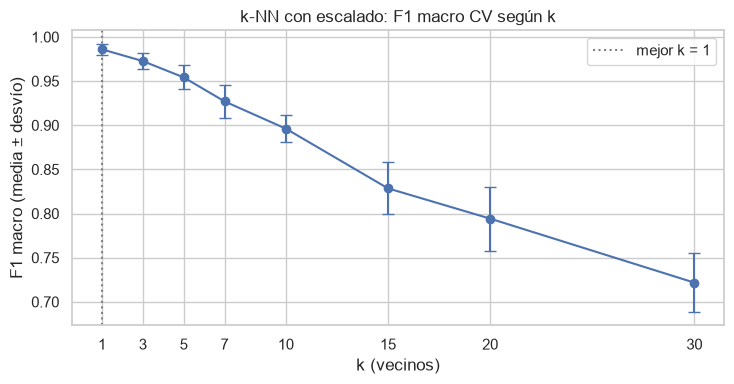

In [4]:
# 11.2 Exploración de k con CV de 10 folds (solo train)
ks = [1, 3, 5, 7, 10, 15, 20, 30]
medias, desvios = [], []
for k in ks:
    scores = cross_val_score(crear_pipeline_completo(KNeighborsClassifier(n_neighbors=k)),
                             X_train, y_train, cv=cv10, scoring="f1_macro", n_jobs=-1)
    medias.append(scores.mean())
    desvios.append(scores.std())

curva_k = pd.DataFrame({"F1 macro CV media": medias, "F1 macro CV desvío": desvios}, index=pd.Index(ks, name="k"))
display(curva_k.round(4))

mejor_k = curva_k["F1 macro CV media"].idxmax()
plt.figure(figsize=(7.5, 4))
plt.errorbar(ks, medias, yerr=desvios, fmt="o-", capsize=4)
plt.axvline(mejor_k, color="gray", ls=":", label=f"mejor k = {mejor_k}")
plt.title("k-NN con escalado: F1 macro CV según k")
plt.xlabel("k (vecinos)")
plt.ylabel("F1 macro (media ± desvío)")
plt.xticks(ks)
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
# 11.3 k-NN con el k elegido por CV: se suma a la tabla de modelos
knn_mejor = crear_pipeline_completo(KNeighborsClassifier(n_neighbors=mejor_k)).fit(X_train, y_train)
pred = knn_mejor.predict(X_test)
filas.append({"Modelo": f"k-NN k={mejor_k} con escalado",
              "F1 macro CV media": curva_k.loc[mejor_k, "F1 macro CV media"],
              "F1 macro CV desvío": curva_k.loc[mejor_k, "F1 macro CV desvío"],
              "F1 macro test": f1_score(y_test, pred, average="macro")})
print("Accuracy test del mejor k:", round(accuracy_score(y_test, pred), 4))
pd.DataFrame(filas).set_index("Modelo").round(4)

Accuracy test del mejor k: 0.9939


,F1 macro CV media,F1 macro CV desvío,F1 macro test
Modelo,,,
k-NN k=5 sin escalado,0.9126,0.0149,0.9162
k-NN k=5 con escalado,0.9542,0.0136,0.9675
k-NN k=1 con escalado,0.9859,0.0062,0.9941


### Explicación del alumno/a

**Decisiones técnicas y justificación:**
- **Comparación con k = 5:**
  - **Sin escalado:** one-hot + numéricas crudas.
  - **Con escalado correcto:** el preprocesamiento de la Actividad 09, con el `StandardScaler` **dentro del pipeline**, ajustado solo con el train de cada fold.
- **Exploración de k:** k ∈ {1, 3, 5, 7, 10, 15, 20, 30} con la CV estratificada de 10 folds sobre train, reportando media ± std.
- **Elección de k:** la mejor media de CV, sin mirar test. El k-NN elegido se suma a la tabla de modelos.

**Interpretación de los resultados:**
- **Efecto del escalado:** sin escalar, el F1 CV es 0,913 ± 0,015 (0,916 en test); con escalado sube a **0,954 ± 0,014** (0,968 en test). Sin escalar, `Metros1` y `Metros2` tienen rangos de ~9.400 m, frente a 9 años y dummies de 0/1, así que dominan la distancia.
- **Curva de k:** el F1 baja de forma monótona con k: 0,986 (k = 1), 0,973 (k = 3), 0,954 (k = 5)… hasta 0,722 (k = 30). El mejor es **k = 1**, con 0,9859 ± 0,0062 en CV y 0,994 en test.
- **Por qué gana k = 1:** con el escalado, compartir sucursal y tela pesa mucho en la distancia, y el formato es constante para cada par. El vecino más cercano suele ser **el mismo par en otro año**, así que k = 1 funciona como una tabla de búsqueda. Con más vecinos se mezclan pares distintos y empeora.

**Pregunta de análisis:** ¿Por qué k-NN cambia con la escala y Random Forest generalmente no? ¿Cómo justificás k?
- **k-NN y la escala:** k-NN decide por distancia euclídea, y una variable con un rango 1.000 veces mayor pesa 1.000 veces más en esa distancia. Cambiar unidades cambia los vecinos.
- **RF y la escala:** cada árbol hace cortes del tipo "x ≤ umbral" sobre una sola variable a la vez. Una transformación monótona como el escalado mueve el umbral, pero no cambia qué filas quedan de cada lado, así que el modelo resultante es equivalente.
- **Cómo justificamos k:** con la CV de train, no con test. k = 1 maximiza la media y además tiene el menor desvío.
  - Igual lo tomamos con cautela: es el extremo de la grilla y en general es el más sensible al ruido.
  - Acá funciona por la estructura de pares repetidos, que no existiría ante sucursales o telas nuevas.
  - Si se busca robustez, k = 3 (0,973) es un compromiso razonable.
  - La Unidad 6 propone k ≈ √n como punto de partida (√2.628 ≈ 51). Acá ese valor suavizaría demasiado: con k = 30 el F1 ya cae a 0,722. Por eso k se elige con CV, como indica la misma teoría.
  - La teoría también asocia k pequeño con bajo sesgo y alta varianza (riesgo de sobreajuste). En la Actividad 13, con una CV agrupada por par, k = 1 cae de 0,986 a 0,698: el resultado de la CV aleatoria refleja memoria de pares conocidos, no generalización.

**Limitaciones o mejoras posibles:**
- k-NN guarda todo el train, predice más lento a medida que crecen los datos y no generaliza a pares nuevos.
- Se podría ponderar por distancia (`weights='distance'`) o ajustar el peso relativo de las dummies frente a las numéricas.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]
